# Assignment–02: Comparative Study and Practical Analysis of Generative AI Models

**CO3:** Autoencoder (AE) and Variational Autoencoder (VAE) – image reconstruction  
**CO4:** Deep Convolutional GAN (DCGAN) and pretrained Diffusion Model – image generation

### Group members
- Amruta Kanase — PRN: 202401110042
- Sanika Mane — PRN: 202401110047
- Tanishka Tapkir — PRN: 202401110071



## 1. Install and import libraries

In [1]:
!pip -q install -U diffusers transformers accelerate safetensors

In [2]:
import time
import torch
from diffusers import StableDiffusionPipeline

In [2]:
import os, glob, tarfile, urllib.request, random, time, math
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download LFW dataset directly into Colab


In [3]:
DATA_DIR = "/content/lfw_data"
ARCHIVE_PATH = os.path.join(DATA_DIR, "lfw-funneled.tgz")
ARCHIVE_URL = "https://ndownloader.figshare.com/files/5976015"

os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(ARCHIVE_PATH):
    print("Downloading LFW archive. Please wait...")
    urllib.request.urlretrieve(ARCHIVE_URL, ARCHIVE_PATH)
    print("Download finished.")
else:
    print("Archive already exists in this runtime.")

EXTRACT_MARKER = os.path.join(DATA_DIR, "extracted.txt")
if not os.path.exists(EXTRACT_MARKER):
    print("Extracting archive...")
    with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:
        tar.extractall(path=DATA_DIR)
    with open(EXTRACT_MARKER, "w") as f:
        f.write("done")

image_paths = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True))
print("Number of JPG images found:", len(image_paths))
print("Example image:", image_paths[0] if image_paths else "No images found")

if len(image_paths) == 0:
    raise RuntimeError("No images found. Re-run the download/extraction cell and check the internet connection.")

Download finished.
Extracting archive...


/tmp/ipykernel_638/184327522.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=DATA_DIR)


Number of JPG images found: 13233
Example image: /content/lfw_data/lfw_funneled/AJ_Cook/AJ_Cook_0001.jpg


## 3. Preprocess images and create all shared dataset variables
This cell defines `X`, `train_x`, `test_x`, `train_ds`, `test_ds`, and `gan_ds`. All later model cells use these exact variable names. Run this cell before training any model.

In [4]:
IMG_SIZE = 64
MAX_IMAGES = 3000       # Smaller subset to reduce execution time.
BATCH_SIZE = 64

# Shuffle before selecting so the subset is not restricted to alphabetic folder order.
random.shuffle(image_paths)
selected_paths = image_paths[:min(MAX_IMAGES, len(image_paths))]
print("Selected image count:", len(selected_paths))

def load_face(path):
    with Image.open(path) as img:
        img = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        return np.asarray(img, dtype=np.float32) / 255.0

X = np.stack([load_face(path) for path in selected_paths]).astype("float32")
print("X shape:", X.shape)
print("Pixel range:", float(X.min()), "to", float(X.max()))

# 90% training, 10% validation/test split
indices = np.random.permutation(len(X))
split_index = int(0.9 * len(X))
train_x = X[indices[:split_index]]
test_x = X[indices[split_index:]]

# AE/VAE need input-target pairs because they learn to reproduce their input.
train_ds = tf.data.Dataset.from_tensor_slices((train_x, train_x))
train_ds = train_ds.shuffle(min(1000, len(train_x)), seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((test_x, test_x))
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# DCGAN uses real images only.
gan_ds = tf.data.Dataset.from_tensor_slices(train_x)
gan_ds = gan_ds.shuffle(min(1000, len(train_x)), seed=SEED).batch(BATCH_SIZE, drop_remainder=True).prefetch(tf.data.AUTOTUNE)

print("Training images:", len(train_x))
print("Validation images:", len(test_x))
print("Training batches:", len(train_ds))
print("Preprocessing completed successfully.")

Selected image count: 3000
X shape: (3000, 64, 64, 3)
Pixel range: 0.0 to 1.0
Training images: 2700
Validation images: 300
Training batches: 43
Preprocessing completed successfully.


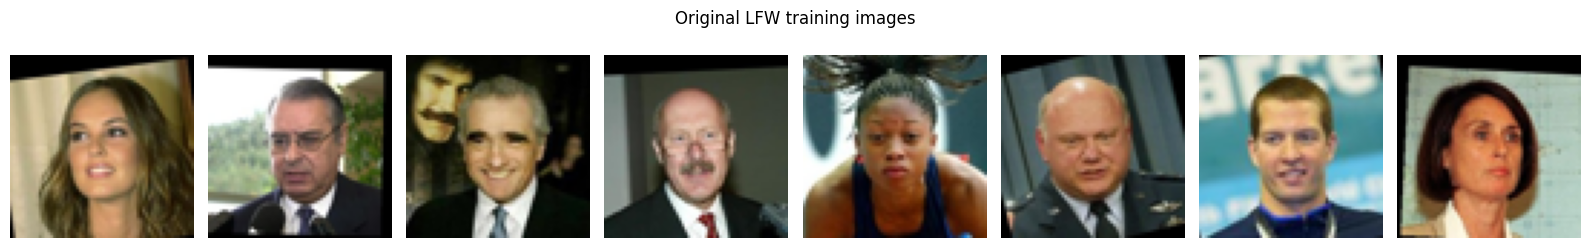

In [5]:
def show_images(images, title, count=8):
    count = min(count, len(images))
    fig, axes = plt.subplots(1, count, figsize=(2 * count, 2.5))
    if count == 1:
        axes = [axes]
    for ax, image in zip(axes, images[:count]):
        ax.imshow(np.clip(image, 0, 1))
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_images(train_x, "Original LFW training images")

## 4. Autoencoder (AE) – image reconstruction
The encoder compresses each 64×64 image into a 128-dimensional latent vector. The decoder reconstructs the image from this vector.

In [6]:
LATENT_DIM = 128

def build_autoencoder():
    inp = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # Encoder: 64x64 -> 32x32 -> 16x16 -> 8x8
    x = tf.keras.layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(inp)
    x = tf.keras.layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
    x = tf.keras.layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)

    shape_before_flatten = tuple(int(dim) for dim in x.shape[1:])
    x = tf.keras.layers.Flatten()(x)
    z = tf.keras.layers.Dense(LATENT_DIM, name="latent_vector")(x)
    encoder = tf.keras.Model(inp, z, name="AE_Encoder")

    # Decoder: 8x8 -> 16x16 -> 32x32 -> 64x64
    z_in = tf.keras.Input(shape=(LATENT_DIM,))
    y = tf.keras.layers.Dense(int(np.prod(shape_before_flatten)), activation="relu")(z_in)
    y = tf.keras.layers.Reshape(shape_before_flatten)(y)
    y = tf.keras.layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(y)
    y = tf.keras.layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(y)
    y = tf.keras.layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(y)
    out = tf.keras.layers.Conv2D(3, 3, padding="same", activation="sigmoid")(y)

    decoder = tf.keras.Model(z_in, out, name="AE_Decoder")
    autoencoder = tf.keras.Model(inp, decoder(encoder(inp)), name="Autoencoder")
    return encoder, decoder, autoencoder

ae_encoder, ae_decoder, ae = build_autoencoder()
ae.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
ae.summary()

Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AE_Encoder (Functional)         │ (None, 128)            │     1,141,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AE_Decoder (Functional)         │ (None, 64, 64, 3)      │     1,297,475 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,439,427 (9.31 MB)

 Trainable params: 2,439,427 (9.31 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
EPOCHS_AE = 10
ae_start = time.time()
ae_history = ae.fit(train_ds, validation_data=test_ds, epochs=EPOCHS_AE)
ae_training_seconds = time.time() - ae_start
print(f"AE training time: {ae_training_seconds:.1f} seconds")

Epoch 1/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 20s 238ms/step - loss: 0.0714 - val_loss: 0.0548
Epoch 2/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0434 - val_loss: 0.0352
Epoch 3/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0312 - val_loss: 0.0278
Epoch 4/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0253 - val_loss: 0.0236
Epoch 5/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0219 - val_loss: 0.0209
Epoch 6/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0194 - val_loss: 0.0189
Epoch 7/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0173 - val_loss: 0.0170
Epoch 8/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0156 - val_loss: 0.0158
Epoch 9/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0142 - val_loss: 0.0151
Epoch 10/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0130 - val_loss: 0.0144
AE training time: 31.1 seconds


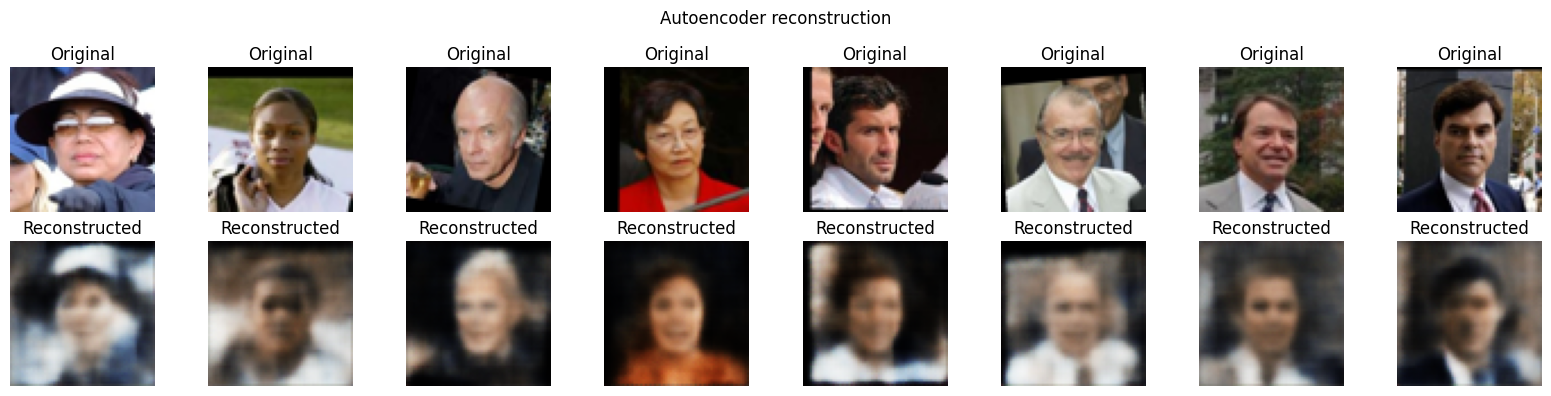

In [8]:
ae_reconstructed = ae.predict(test_x[:8], verbose=0)

def compare_original_reconstructed(original, reconstructed, title):
    n = min(len(original), len(reconstructed), 8)
    fig, axes = plt.subplots(2, n, figsize=(2*n, 4))
    for i in range(n):
        axes[0, i].imshow(np.clip(original[i], 0, 1))
        axes[0, i].set_title("Original")
        axes[1, i].imshow(np.clip(reconstructed[i], 0, 1))
        axes[1, i].set_title("Reconstructed")
        axes[0, i].axis("off")
        axes[1, i].axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

compare_original_reconstructed(test_x[:8], ae_reconstructed, "Autoencoder reconstruction")

## 5. Variational Autoencoder (VAE) – image reconstruction
The VAE encoder learns a mean and log-variance for a probability distribution. A latent vector is sampled from this distribution and passed to the decoder.

In [9]:
VAE_LATENT_DIM = 128

vae_input = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
h = tf.keras.layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(vae_input)
h = tf.keras.layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(h)
h = tf.keras.layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(h)
h = tf.keras.layers.Flatten()(h)
h = tf.keras.layers.Dense(256, activation="relu")(h)
z_mean = tf.keras.layers.Dense(VAE_LATENT_DIM, name="z_mean")(h)
z_log_var = tf.keras.layers.Dense(VAE_LATENT_DIM, name="z_log_var")(h)

class Sampling(tf.keras.layers.Layer):
    def call(self, inputs):
        mean, log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(mean))
        return mean + tf.exp(0.5 * log_var) * epsilon

z_sample = Sampling()([z_mean, z_log_var])
vae_encoder = tf.keras.Model(vae_input, [z_mean, z_log_var, z_sample], name="VAE_Encoder")

latent_input = tf.keras.Input(shape=(VAE_LATENT_DIM,))
d = tf.keras.layers.Dense(8 * 8 * 128, activation="relu")(latent_input)
d = tf.keras.layers.Reshape((8, 8, 128))(d)
d = tf.keras.layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(d)
d = tf.keras.layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(d)
d = tf.keras.layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(d)
vae_output = tf.keras.layers.Conv2D(3, 3, padding="same", activation="sigmoid")(d)
vae_decoder = tf.keras.Model(latent_input, vae_output, name="VAE_Decoder")

class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.reconstruction_tracker = tf.keras.metrics.Mean(name="reconstruction_loss")
        self.kl_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.reconstruction_tracker, self.kl_tracker]

    def train_step(self, data):
        images = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            mean, log_var, z = self.encoder(images, training=True)
            reconstruction = self.decoder(z, training=True)
            # Sum pixel/channel losses per image.
            bce = tf.keras.backend.binary_crossentropy(images, reconstruction)
            reconstruction_loss = tf.reduce_mean(tf.reduce_sum(bce, axis=[1, 2, 3]))
            kl_loss = -0.5 * tf.reduce_mean(tf.reduce_sum(
                1 + log_var - tf.square(mean) - tf.exp(log_var), axis=1
            ))
            total_loss = reconstruction_loss + kl_loss
        gradients = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_tracker.update_state(reconstruction_loss)
        self.kl_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}

    def call(self, images, training=False):
        _, _, z = self.encoder(images, training=training)
        return self.decoder(z, training=training)

vae = VAE(vae_encoder, vae_decoder, name="VariationalAutoencoder")
vae.compile(optimizer=tf.keras.optimizers.Adam(1e-3))

Epoch 1/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 10s 98ms/step - kl_loss: 15.8264 - loss: 8040.0176 - reconstruction_loss: 8024.1890
Epoch 2/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - kl_loss: 30.4481 - loss: 7582.5444 - reconstruction_loss: 7552.0981
Epoch 3/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - kl_loss: 41.6393 - loss: 7384.0356 - reconstruction_loss: 7342.3970
Epoch 4/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - kl_loss: 62.3639 - loss: 7143.3989 - reconstruction_loss: 7081.0356
Epoch 5/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - kl_loss: 70.8376 - loss: 7010.1558 - reconstruction_loss: 6939.3184
Epoch 6/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - kl_loss: 75.5719 - loss: 6958.3081 - reconstruction_loss: 6882.7368
Epoch 7/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - kl_loss: 81.1470 - loss: 6887.7368 - reconstruction_loss: 6806.5908
Epoch 8/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - kl_loss: 84.4507 - loss: 6869.6128 - reconstruction_loss: 6785.1611
Epoch 9/10
43/43 ━━━━━━━━━━━━━━

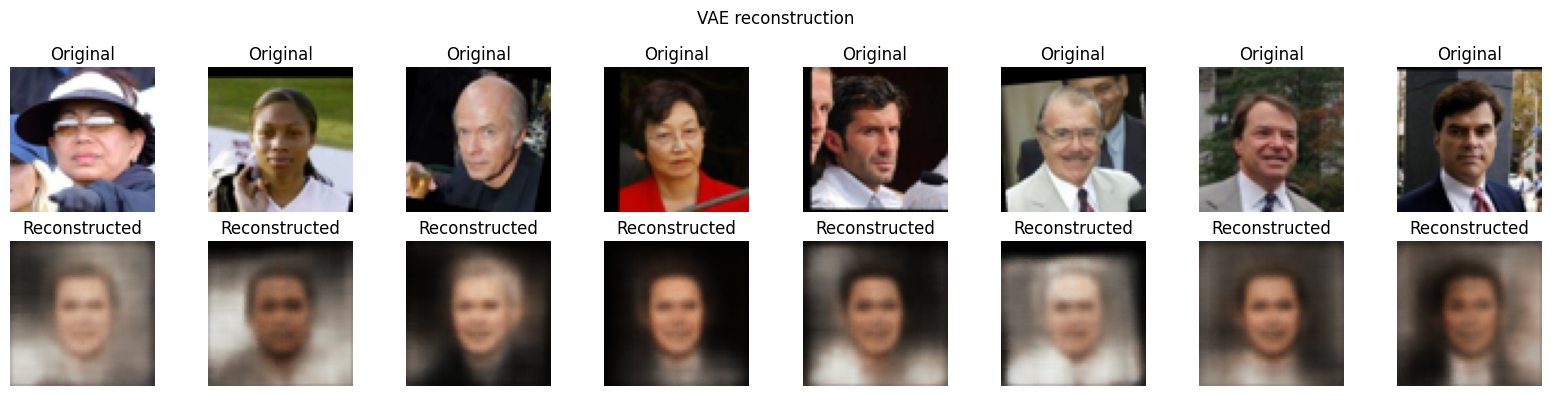

In [10]:
EPOCHS_VAE = 10
vae_start = time.time()
vae_history = vae.fit(train_ds, epochs=EPOCHS_VAE)
vae_training_seconds = time.time() - vae_start
print(f"VAE training time: {vae_training_seconds:.1f} seconds")

vae_reconstructed = vae.predict(test_x[:8], verbose=0)
compare_original_reconstructed(test_x[:8], vae_reconstructed, "VAE reconstruction")

## 6. DCGAN – image generation

DCGAN contains a generator and a discriminator. The generator creates face-like images from random noise, while the discriminator learns to distinguish real training images from generated images.

This version uses:
- A convolutional generator and discriminator.
- A lower discriminator learning rate to reduce the chance that it learns much faster than the generator.
- Batch normalization, dropout, mild discriminator input noise and one-sided label smoothing.
- Fixed random noise for checkpoint images, so outputs can be compared across epochs.

GAN training is sensitive and losses can fluctuate. Thirty epochs may still produce imperfect or blurry faces; the actual output screenshots must be used to judge the result. A GPU runtime is recommended.

In [11]:
NOISE_DIM = 100

# Generator: converts random noise into a 64x64 RGB image in [-1, 1].
generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(NOISE_DIM,)),
    tf.keras.layers.Dense(8 * 8 * 256, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Reshape((8, 8, 256)),

    tf.keras.layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(0.2),

    tf.keras.layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(0.2),

    tf.keras.layers.Conv2DTranspose(3, 4, strides=2, padding="same", activation="tanh")
], name="DCGAN_Generator")

# Discriminator: predicts whether an image is real or generated.
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.GaussianNoise(0.05),
    tf.keras.layers.Conv2D(64, 4, strides=2, padding="same"),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Conv2D(128, 4, strides=2, padding="same"),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Conv2D(256, 4, strides=2, padding="same"),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1)
], name="DCGAN_Discriminator")

cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

# A slower discriminator can help avoid it overpowering the generator.
g_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
d_optimizer = tf.keras.optimizers.Adam(learning_rate=0.00005, beta_1=0.5)

# Fixed noise makes it easier to compare progress from epoch to epoch.
fixed_noise = tf.random.normal([16, NOISE_DIM], seed=SEED)

def dcgan_train_step(real_images):
    batch_n = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_n, NOISE_DIM])

    # Convert real images from [0,1] to [-1,1], matching generator output.
    real_images = real_images * 2.0 - 1.0

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(tf.stop_gradient(fake_images), training=True)

        # One-sided label smoothing: real labels are 0.9 instead of 1.0.
        real_labels = tf.ones_like(real_output) * 0.9
        fake_labels = tf.zeros_like(fake_output)

        gen_loss = cross_entropy(tf.ones_like(fake_output), discriminator(fake_images, training=True))
        disc_loss_real = cross_entropy(real_labels, real_output)
        disc_loss_fake = cross_entropy(fake_labels, fake_output)
        disc_loss = disc_loss_real + disc_loss_fake

    gen_gradients = gen_tape.gradient(gen_loss, generator.trainable_variables)
    disc_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    g_optimizer.apply_gradients(zip(gen_gradients, generator.trainable_variables))
    d_optimizer.apply_gradients(zip(disc_gradients, discriminator.trainable_variables))

    return gen_loss, disc_loss

def display_dcgan_samples(title):
    generated = generator(fixed_noise, training=False)
    generated = (generated + 1.0) / 2.0
    fig, axes = plt.subplots(4, 4, figsize=(7, 7))
    for ax, img in zip(axes.flat, generated):
        ax.imshow(np.clip(img.numpy(), 0, 1))
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

generator.summary()

Model: "DCGAN_Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16384)          │     1,638,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16384)          │        65,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 16, 16, 128)    │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 32, 32, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 64, 64, 3)      │         3,075 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,363,139 (9.01 MB)

 Trainable params: 2,329,987 (8.89 MB)

 Non-trainable params: 33,152 (129.50 KB)

Epoch 01/30 | Generator loss: 0.7107 | Discriminator loss: 1.2755


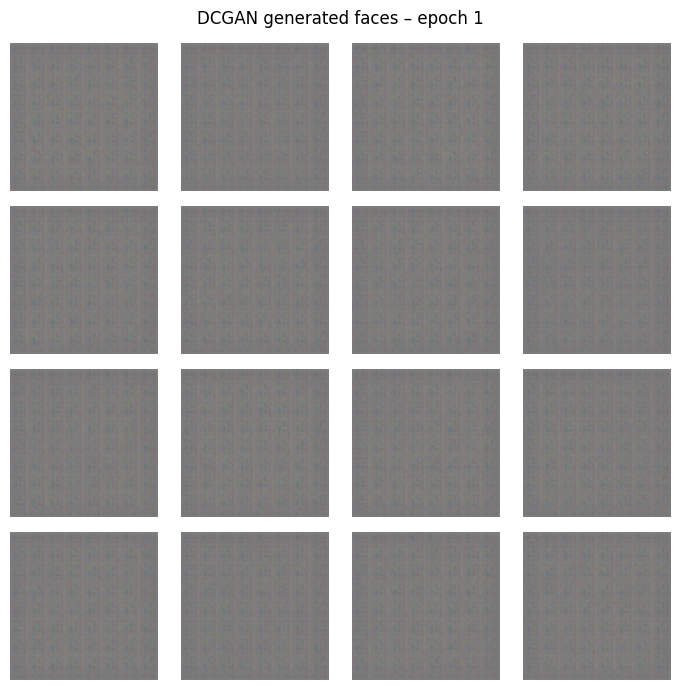

Epoch 02/30 | Generator loss: 0.8424 | Discriminator loss: 1.2072
Epoch 03/30 | Generator loss: 0.8199 | Discriminator loss: 1.3754
Epoch 04/30 | Generator loss: 0.7780 | Discriminator loss: 1.4514
Epoch 05/30 | Generator loss: 0.7942 | Discriminator loss: 1.4382


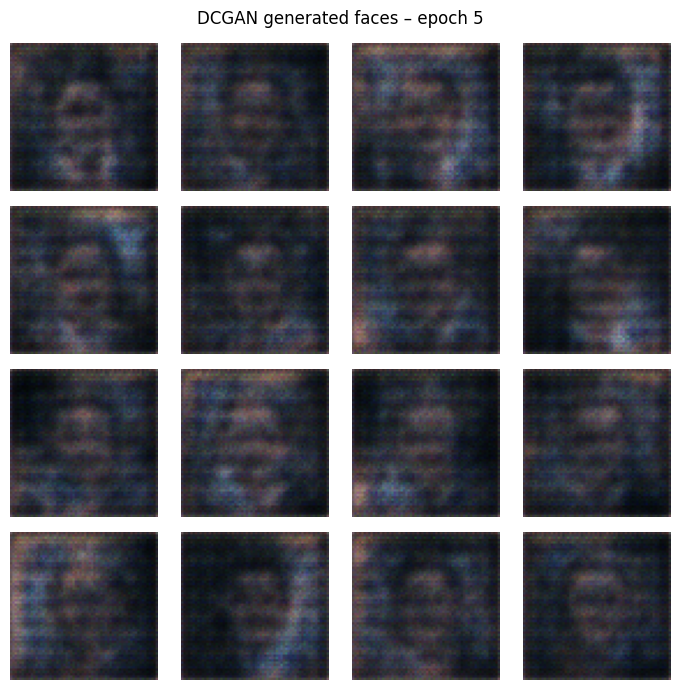

Epoch 06/30 | Generator loss: 0.8032 | Discriminator loss: 1.4179
Epoch 07/30 | Generator loss: 0.7789 | Discriminator loss: 1.4110
Epoch 08/30 | Generator loss: 0.8037 | Discriminator loss: 1.4009
Epoch 09/30 | Generator loss: 0.7836 | Discriminator loss: 1.3949
Epoch 10/30 | Generator loss: 0.7893 | Discriminator loss: 1.4023


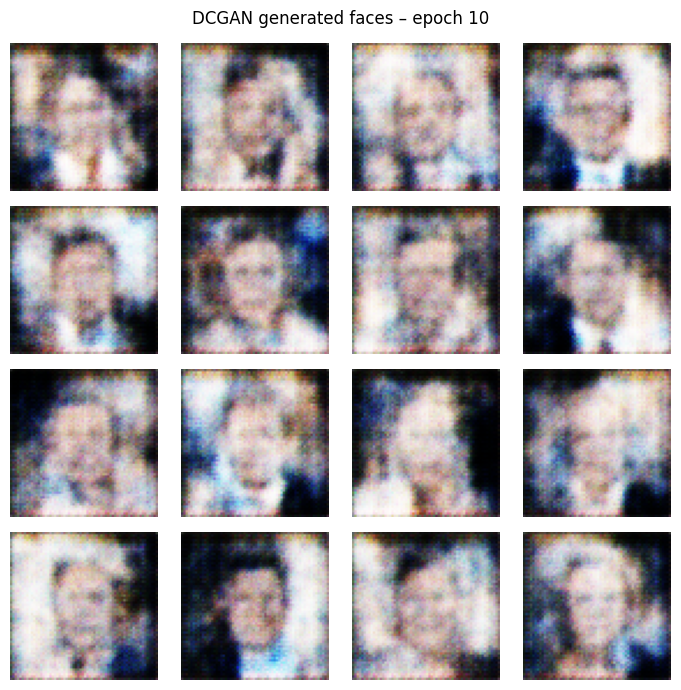

Epoch 11/30 | Generator loss: 0.7900 | Discriminator loss: 1.3919
Epoch 12/30 | Generator loss: 0.7505 | Discriminator loss: 1.4053
Epoch 13/30 | Generator loss: 0.7767 | Discriminator loss: 1.3982
Epoch 14/30 | Generator loss: 0.7705 | Discriminator loss: 1.3982
Epoch 15/30 | Generator loss: 0.7703 | Discriminator loss: 1.3915


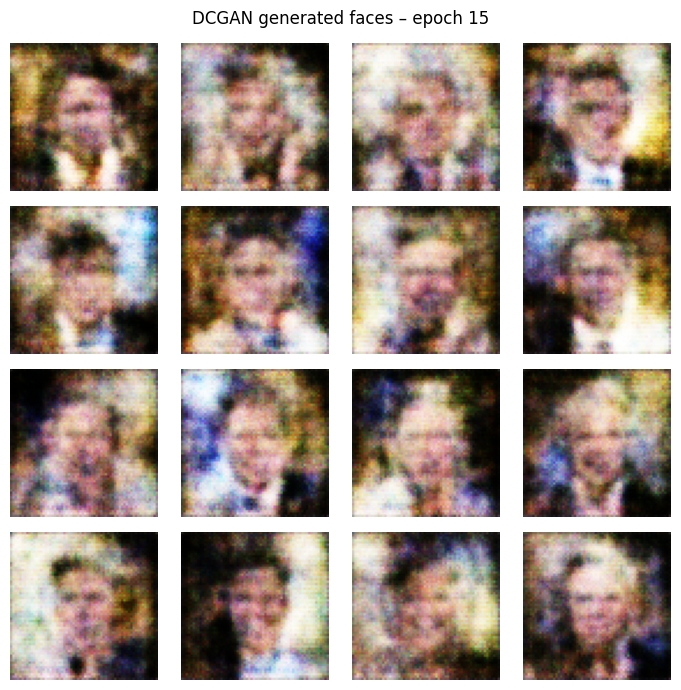

Epoch 16/30 | Generator loss: 0.7717 | Discriminator loss: 1.3918
Epoch 17/30 | Generator loss: 0.7662 | Discriminator loss: 1.3911
Epoch 18/30 | Generator loss: 0.7724 | Discriminator loss: 1.3915
Epoch 19/30 | Generator loss: 0.7796 | Discriminator loss: 1.3903
Epoch 20/30 | Generator loss: 0.7774 | Discriminator loss: 1.3879


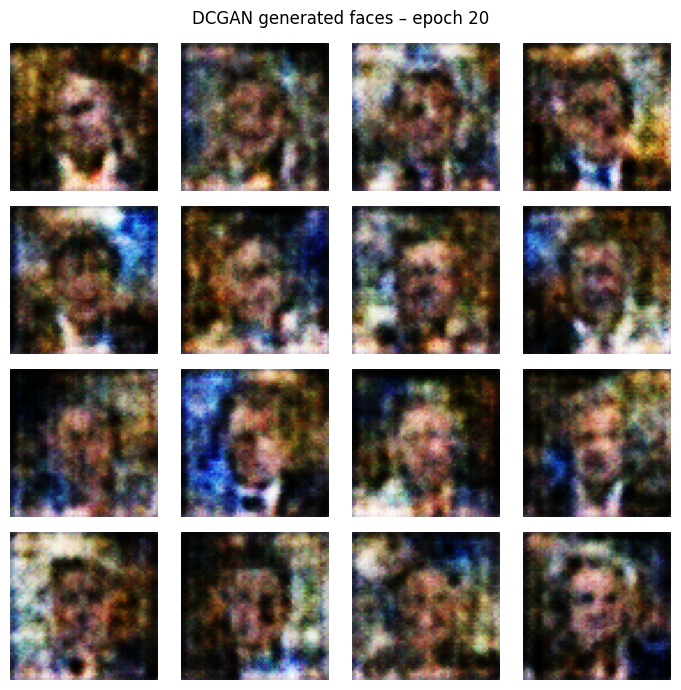

Epoch 21/30 | Generator loss: 0.7813 | Discriminator loss: 1.3872
Epoch 22/30 | Generator loss: 0.7839 | Discriminator loss: 1.3862
Epoch 23/30 | Generator loss: 0.7843 | Discriminator loss: 1.3858
Epoch 24/30 | Generator loss: 0.7857 | Discriminator loss: 1.3811
Epoch 25/30 | Generator loss: 0.7821 | Discriminator loss: 1.3871


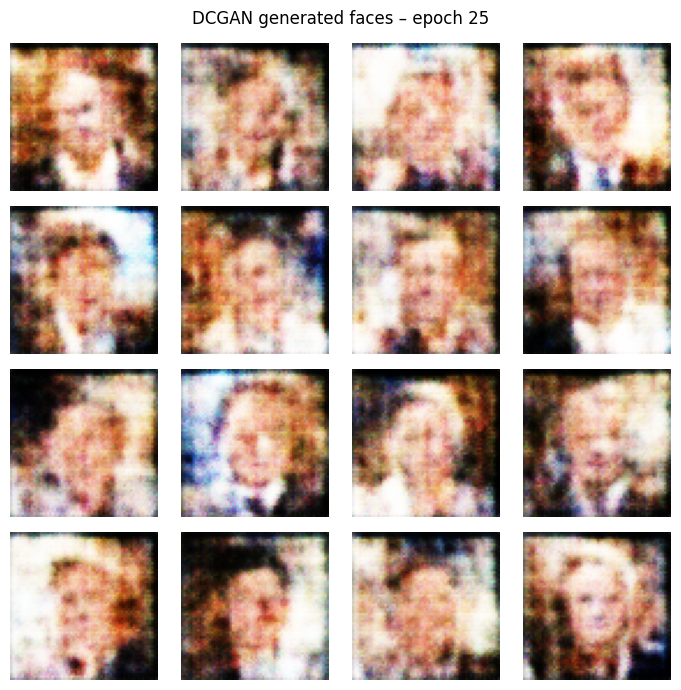

Epoch 26/30 | Generator loss: 0.7849 | Discriminator loss: 1.3869
Epoch 27/30 | Generator loss: 0.7822 | Discriminator loss: 1.3828
Epoch 28/30 | Generator loss: 0.7816 | Discriminator loss: 1.3835
Epoch 29/30 | Generator loss: 0.7822 | Discriminator loss: 1.3829
Epoch 30/30 | Generator loss: 0.7858 | Discriminator loss: 1.3831


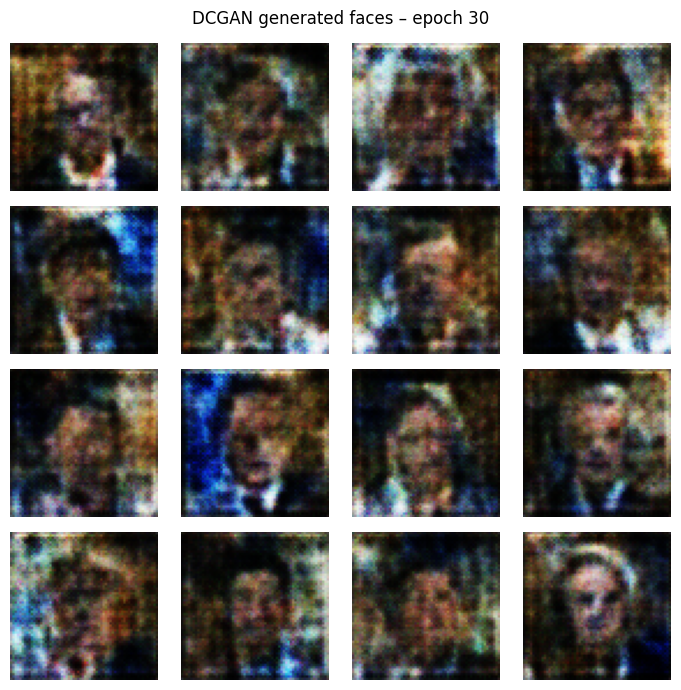

DCGAN training time: 333.6 seconds


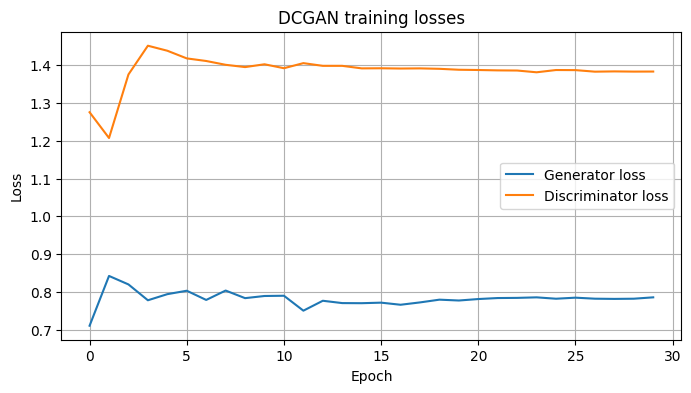

In [12]:
GAN_EPOCHS = 30
gan_start = time.time()
gan_generator_losses = []
gan_discriminator_losses = []

for epoch in range(1, GAN_EPOCHS + 1):
    g_losses, d_losses = [], []

    for real_batch in gan_ds:
        g_loss, d_loss = dcgan_train_step(real_batch)
        g_losses.append(float(g_loss.numpy()))
        d_losses.append(float(d_loss.numpy()))

    mean_g = float(np.mean(g_losses))
    mean_d = float(np.mean(d_losses))
    gan_generator_losses.append(mean_g)
    gan_discriminator_losses.append(mean_d)

    print(
        f"Epoch {epoch:02d}/{GAN_EPOCHS} | "
        f"Generator loss: {mean_g:.4f} | "
        f"Discriminator loss: {mean_d:.4f}"
    )

    # Display fixed-noise samples at selected checkpoints.
    if epoch in [1, 5, 10, 15, 20, 25, 30]:
        display_dcgan_samples(f"DCGAN generated faces – epoch {epoch}")

gan_training_seconds = time.time() - gan_start
print(f"DCGAN training time: {gan_training_seconds:.1f} seconds")

# Plot loss curves. GAN losses may fluctuate; they do not need to decrease smoothly.
plt.figure(figsize=(8, 4))
plt.plot(gan_generator_losses, label="Generator loss")
plt.plot(gan_discriminator_losses, label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN training losses")
plt.legend()
plt.grid(True)
plt.show()

## 7. Pretrained Diffusion Model – text-to-image

This section uses the pretrained `segmind/tiny-sd` model to generate an image from a text prompt. It is not trained on the LFW dataset. A GPU is strongly recommended. The first run downloads model weights and can take several minutes. Model availability and runtime depend on the Colab environment and the model host.

Diffusion device: cuda


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


  0%|          | 0/20 [00:00<?, ?it/s]

Prompt: A realistic portrait photograph of a person, soft natural daylight, neutral background, high detail
Generation time: 3.3 seconds


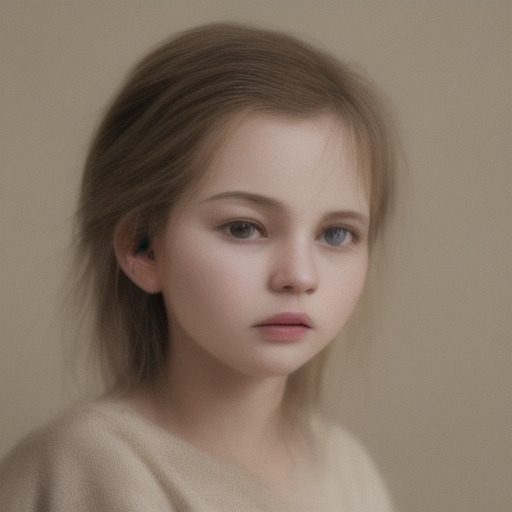

In [3]:
# Install/import diffusion libraries if needed.
import torch
from diffusers import StableDiffusionPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "segmind/tiny-sd"

print("Diffusion device:", device)
if device == "cpu":
    print("Warning: Diffusion generation on CPU can be very slow. A Colab GPU is recommended.")

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    safety_checker=None
)
pipe = pipe.to(device)

prompt = "A realistic portrait photograph of a person, soft natural daylight, neutral background, high detail"
diffusion_start = time.time()
with torch.inference_mode():
    diffusion_result = pipe(prompt, num_inference_steps=20, guidance_scale=7.0)
diffusion_seconds = time.time() - diffusion_start

diffusion_image = diffusion_result.images[0]
print("Prompt:", prompt)
print(f"Generation time: {diffusion_seconds:.1f} seconds")
display(diffusion_image)

## 8. Practical observations and timing


In [5]:
print("========== MODEL EXECUTION TIMES ==========")

if "ae_training_seconds" in globals():
    print("AE training time:", round(ae_training_seconds, 2), "seconds")
else:
    print("AE training time: Not recorded")

if "vae_training_seconds" in globals():
    print("VAE training time:", round(vae_training_seconds, 2), "seconds")
else:
    print("VAE training time: Not recorded")

if "gan_training_seconds" in globals():
    print("DCGAN training time:", round(gan_training_seconds, 2), "seconds")
else:
    print("DCGAN training time: Not recorded")

if "diffusion_seconds" in globals():
    print("Diffusion generation time:", round(diffusion_seconds, 2), "seconds")
else:
    print("Diffusion generation time: Not recorded")

print("==========================================")

========== MODEL EXECUTION TIMES ==========
AE training time: Not recorded
VAE training time: Not recorded
DCGAN training time: Not recorded
Diffusion generation time: 3.34 seconds


### Observation prompts
- **AE:** Are the main face shapes and colours retained? Are details blurred?
- **VAE:** Does the reconstruction look smoother? Are fine details lost?
- **DCGAN:** Do generated samples look face-like? Are samples varied or repeated?
- **Diffusion:** Does the generated image match the text prompt? How detailed and realistic is it?
- **Efficiency:** Compare measured training/generation times from your Colab session.

## 9. Final comparison table

| Model | Main task | Key output to inspect |
|---|---|---|
| Autoencoder (AE) | Reconstruct an input image | Similarity to original; blur and lost details |
| Variational Autoencoder (VAE) | Reconstruct and learn a probabilistic latent space | Smoothness, similarity and variation |
| DCGAN | Generate new images from random noise | Realism, diversity and repeated patterns |
| Pretrained Diffusion | Generate a new image from a text prompt | Prompt relevance, realism, details and runtime |


